<a href="https://colab.research.google.com/github/TZBDragon/LinAlg344TZB/blob/main/notebooks/02_svd_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Imports nessecary for the work
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
#From the skimage package take data and select the camera element with type float
A = data.camera().astype(float)
#Print the shape (nxm) and type, which is float because we chose that
print(A.shape, A.dtype)

(512, 512) float64


In [ ]:
#Find SVD of a and assign them to U, s and Vt
U, s, Vt = np.linalg.svd(A, full_matrices=False)
#Find shapes of our derive matricies
print('U:', U.shape, 's:', s.shape, 'Vt:', Vt.shape)
#Remultiply out U, s, and Vt, which as long as there is little to no error should give us A back
A_back = U @ np.diag(s) @ Vt
print('Rebuilt correctly?', np.allclose(A, A_back))
# How big is that error anyway?
print('Largest error:', np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.503952600818593e-11


First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


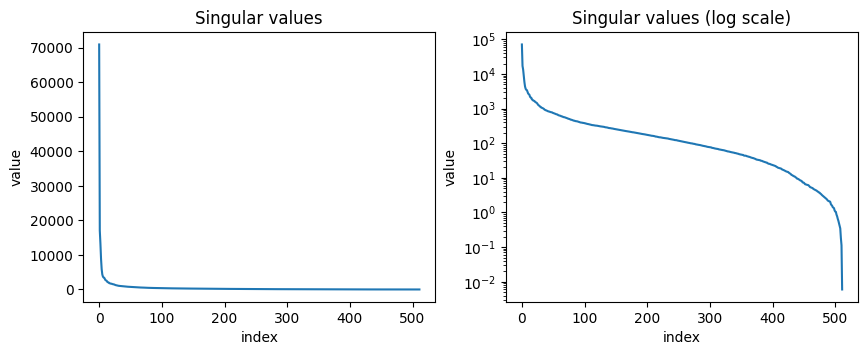

In [ ]:
#Print the first 5 elements of s, rounded to the nearest whole number
print('First five:', np.round(s[:5], 1))
#Print the 50th, 200th, and last elements rounded to a whole number
print('50th, 200th, last:', round(s[49], 1),
round(s[199], 1), round(s[-1], 3))
#Create a figure with 2 axis and set the size of the figure to 10 by 3.5
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
#s is the first axis
ax1.plot(s)
ax1.set(title='Singular values', xlabel='index', ylabel='value')
#plot s as a semi logarithmic plot
ax2.semilogy(s)
ax2.set(title='Singular values (log scale)', xlabel='index', ylabel='value')
#Show the plots
plt.show()

In [ ]:
def rank_k_approx(A, k):
#Return the rank-k SVD approximation of A.
  U, s, Vt = np.linalg.svd(A, full_matrices=False)
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

In [ ]:
print('rank of A_10:', np.linalg.matrix_rank(rank_k_approx(A, 10)))
print('k = 512 gives A back?', np.allclose(rank_k_approx(A, 512), A))
stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print('singular values of stripes:',
np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


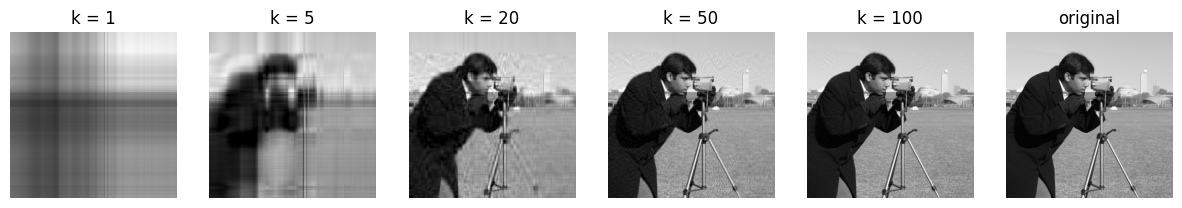

In [ ]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  ax.imshow(Ak, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'k = {k}')
  ax.axis('off')

axes[-1].imshow(A, cmap='gray', vmin=0, vmax=255)
axes[-1].set_title('original')
axes[-1].axis('off')
plt.show()

In [ ]:
m = np.array([[3,0],[4,5]])
eigvals_m = np.linalg.eigvals(m)
print('Eigenvalues of m:', eigvals_m)
mt_m = m.T @ m
eigvals_mt_m = np.linalg.eigvals(mt_m)
singular_values_from_eig = np.sqrt(np.sort(eigvals_mt_m)[::-1])
print('Singular values calculated from eigenvalues of m.T @ m:', singular_values_from_eig)
direct_singular_values = np.linalg.svd(m, compute_uv=False)
print('Direct singular values from SVD:', direct_singular_values)

Eigenvalues of m: [5. 3.]
Singular values calculated from eigenvalues of m.T @ m: [6.70820393 2.23606798]
Direct singular values from SVD: [6.70820393 2.23606798]


In [ ]:
print(np.linalg.norm(A - rank_k_approx(A, 20)))
print(np.sqrt(np.sum(s[20:]**2)))

7699.9091419681245
7699.9091419681245


Saving TZB_9836.JPG to TZB_9836 (1).JPG
Shape: (534, 800)
Data type: uint8


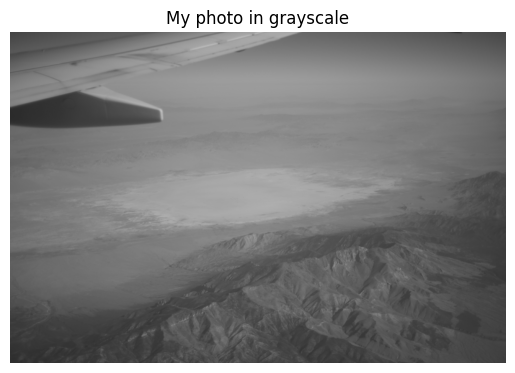

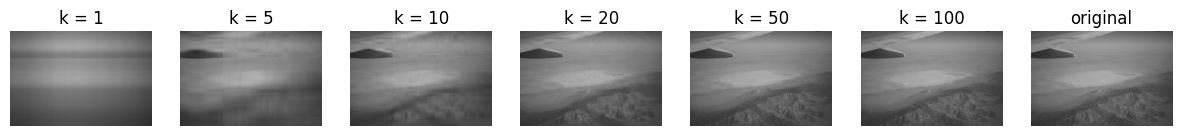

In [ ]:
from google.colab import files
from PIL import Image
uploaded = files.upload()
name = list(uploaded)[0]
img = Image.open(name).convert("L")
img.thumbnail((800, 800))
P = np.array(img)
print("Shape:", P.shape)
print("Data type:", P.dtype)
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")
plt.show()

ks = [1, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Pk = np.clip(rank_k_approx(P, k), 0, 255)
  ax.imshow(Pk, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'k = {k}')
  ax.axis('off')

axes[-1].imshow(P, cmap='gray', vmin=0, vmax=255)
axes[-1].set_title('original')
axes[-1].axis('off')
plt.show()



It's Shockingly recognizable at k = 20, and still discernable at k = 5. This is almost certainly because it is an image of a distant landscape. Eveny though it's 6K by 4K there just isn't really any data to be captured so it holds up better under compression